# Vectorized Cointegration & Statistical Arbitrage Engine
**A Systematic Pairs Trading Pipeline with Realistic Microstructure Accounting**

---

### Executive Overview
This research notebook implements an institutional-grade, end-to-end statistical arbitrage pairs trading strategy in Python. The system identifies structural equilibrium between economically linked assets, models spread deviations as a mean-reverting Ornstein-Uhlenbeck process, and executes an automated out-of-sample trading strategy without lookahead bias.

Rather than relying on naive price-ratio heuristics or unconstrained backtesting packages, this notebook enforces strict research hygiene:
1. **Zero Data Leakage:** Strict chronological in-sample (60%) vs. out-of-sample (40%) data partitions; model parameters are never fit on future test data.
2. **Econometric Rigor:** Individual $I(1)$ unit-root verification via Augmented Dickey-Fuller (ADF) tests and residual stationarity screening using Engle-Granger cointegration critical values.
3. **Analytical Parameter Calibration:** Dynamic rolling lookback windows ($W$) calibrated analytically via the discrete Ornstein-Uhlenbeck half-life of mean reversion ($\tau_{1/2}$).
4. **Production Vectorization:** Loop-free state persistence and explicit $+1$ execution lagging (`.shift(1)`) to eliminate forward-looking entry bias.
5. **Microstructure Realism:** Gross return adjustment incorporating rebalance turnover penalties and bid-ask spread execution drag.

---

### Pipeline Architecture
* **Phase 1: Ingestion & Return Diagnostics** | Ingest adjusted price series, evaluate daily log-return stylized facts, and verify non-normality via Jarque-Bera diagnostics.
* **Phase 2: Econometric Screening & Half-Life Estimation** | Validate $I(1)/I(0)$ integration orders, run Engle-Granger cointegration OLS, and estimate the OU mean-reversion speed.
* **Phase 3: Vectorized Signal Generation** | Construct rolling dynamic $Z$-scores, apply entry/exit/stop-loss state machines, and enforce execution lagging.
* **Phase 4 & 5: Performance Attribution & Risk Diagnostics** | Compute net PnL after transaction friction, annualized Sharpe ratio, maximum drawdown via cumulative peak tracking, and Calmar ratios.

### Phase 1: Ingestion & Summary Statistics

[*********************100%***********************]  2 of 2 completed

Ticker           R_t_XOM        R_t_CVX
mean        8.934206e-04   8.223491e-04
std dev     1.467664e-02   1.437222e-02
skewness   -4.377299e-01  -7.338927e-01
kurtosis    1.646860e+00   4.044904e+00
JB p-value  2.308928e-24  1.542039e-126


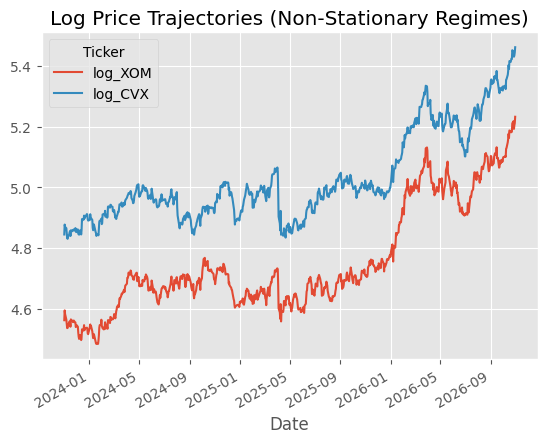

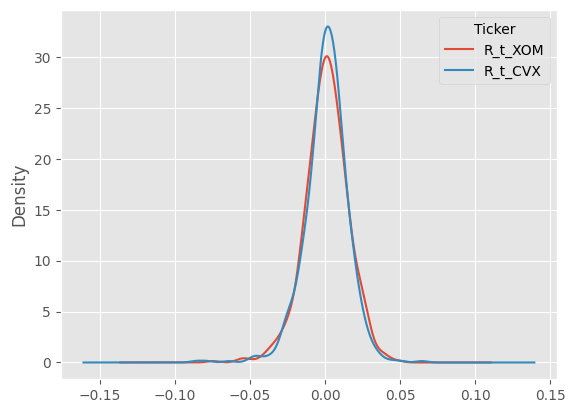

Text(0.5, 1.0, 'Hedge Ratio OLS Geometry')

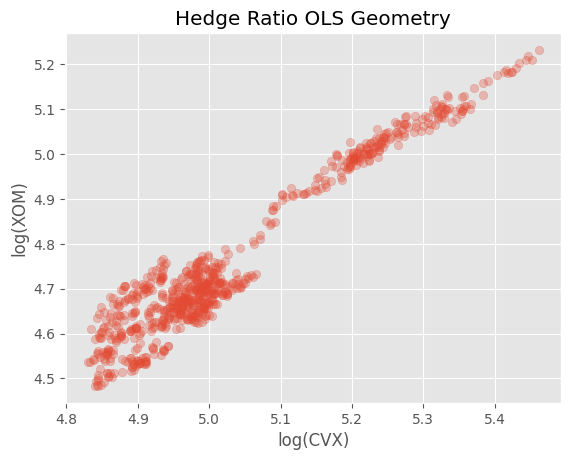

In [100]:
import pandas as pd
import numpy as np
import yfinance as yf
from scipy import stats as sp_stats
import matplotlib.pyplot as plt

np.random.seed(1234)
%matplotlib inline
plt.style.use('ggplot')

raw_data = yf.download(['XOM', 'CVX'], start='2023-11-01', end='2026-11-01')

df = raw_data['Close'].dropna().sort_index()

# Log prices
df['log_XOM'] = np.log(df['XOM'])
df['log_CVX'] = np.log(df['CVX'])
target_cols = ['log_XOM', 'log_CVX']

# Daily returns
df['R_t_XOM'] = np.log(df['XOM']).diff()
df['R_t_CVX'] = np.log(df['CVX']).diff()
target_cols_diff = ['R_t_XOM', 'R_t_CVX']

def compute_stats(series):
    return pd.Series({
        'mean': series.mean(), # daily mean drift
        'std dev': series.std(), # daily volatility
        'skewness': sp_stats.skew(series.dropna()),
        'kurtosis': sp_stats.kurtosis(series.dropna()),
        'JB p-value': sp_stats.jarque_bera(series.dropna())[1] # Jarque-Bera test
    })

stats = df[target_cols_diff].apply(compute_stats)
print(stats)

df[['log_XOM', 'log_CVX']].plot(title="Log Price Trajectories (Non-Stationary Regimes)")
plt.show()

df[['R_t_XOM', 'R_t_CVX']].dropna().plot(kind='kde')
plt.show()

plt.scatter(df['log_CVX'], df['log_XOM'], alpha=0.3)
plt.xlabel("log(CVX)")
plt.ylabel("log(XOM)")
plt.title("Hedge Ratio OLS Geometry")

### Visualizations
1. The average value of the daily returns (mean) for each of the tickers is $r_t \approx 0.0009$ for XOM, which implies that it has drifted up $e^{0.000934205} - 1 \approx 0.0009$ or just +0.09% a day or 22.6% a year. <br>
    While CVX corresponds to $r_t \approx 0.0008$ or +0.08% a day or 20.1% a year. <br>
2. The standard deviation represent the width of the bell with $1.5%$ for XOM and $1.4%$ for CVX. <br>
3. Skewness measures the asymmetry of the distribution around its mean. In our case, both series are slightly negatively skewed. Downside shocks are more common than upside drift.
4. Kurtosis measures the "tailedness" of the distribution. Both our series exhibit positive kurtosis, indicating a leptokurtic distribution.
5. Lastly, we can safely reject our $H_0$ with $p<0.05$ for the null hypothesis that the two series are normally distributed.

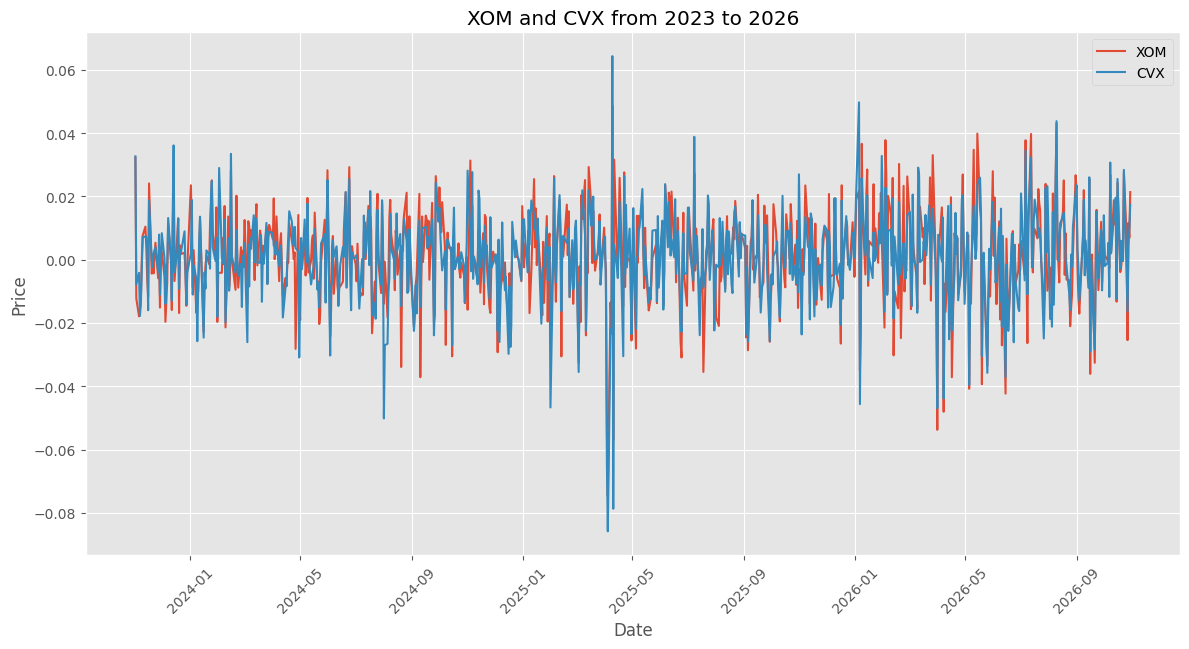

In [101]:
plt.figure(figsize=(12, 6))
plt.plot(df['R_t_XOM'])
plt.plot(df['R_t_CVX'])
plt.xlabel('Date')
plt.ylabel('Price')
plt.legend(['XOM', 'CVX'])
plt.grid(True)
plt.tight_layout()
plt.xticks(rotation=45)
plt.title('XOM and CVX from 2023 to 2026')
plt.show()

### Augmented Dickey-Fuller Tests on log-prices
We perform the ADF test with $H_0$ that the two series have a unit root or possess non-stationarity. We expect the fail to reject the null hypothesis as we need the log-prices to be non-stationary in order to perform cointegration tests later. We must prove that both series are $I(1)$. As a result, we indeed fail to reject the null hypothesis.

### Augmented Dickey-Fuller Tests on log-returns
Our second ADF test consists of confirming whether the log-returns are weakly stationary $I(0)$. This formally proves that both series are of $I(1)$ and not of $+I(2)$ which is a requisite for cointegration. We expect to reject the null hypothesis as the log-returns are stationary and are of order 1 of integration. As a result, we do reject. Hence, we have formally established the prerequisites for Engle-Granger Two-Step Cointegration Test.


In [102]:
from statsmodels.tsa.stattools import adfuller

# Function to perform Augmented Dickey-Fuller test on log-prices
def perform_adf(series):
    result = adfuller(series.dropna())
    print('ADF Stat: %f' % result[0], ', p-value: %f' % result[1])

adf = df[target_cols].apply(perform_adf)
print(adf)

# perform Augmented Dickey-Fuller test on log-returns
adf_diff = df[target_cols_diff].apply(perform_adf)
print(adf_diff)

ADF Stat: 0.184194 , p-value: 0.971361
ADF Stat: 0.003521 , p-value: 0.958822
Ticker
log_XOM    None
log_CVX    None
dtype: object
ADF Stat: -27.374895 , p-value: 0.000000
ADF Stat: -26.477137 , p-value: 0.000000
Ticker
R_t_XOM    None
R_t_CVX    None
dtype: object


### Phase 2: Cointergration Test
We ran a cointegration test on the log-prices using **coint** with $H_0$ that our series are cointegrated. However, we **fail to reject at 5% with a p-value of 0.67**. To successfully reject the null hypothesis at 5% we need a critical value of at least -3.349. In conclusion, although ExxonMobil(XOM) and Chevron(CVX) look like they move together from our first plot and have a clear correlation. They are not cointegrated, in other words their linear spread wanders away like a random walk without circling back to a level/mean. The residuals $\varepsilon_t$ form a non-stationary random walk without mean-reverting properties. We are forced to pivot to another pair. Our choice falls on ETF's of Australia(EWA) and Canada(EWC), two commodity-exporting economies.

In [103]:
from statsmodels.tsa.stattools import coint
# Train/Test split avoiding look-ahead bias
split_idx = int(len(df) * 0.6)

train_df = df.iloc[:split_idx]
test_df = df.iloc[split_idx:]

# run engle-granger test
coint_stat, p_value, crit_values = coint(train_df['log_XOM'], train_df['log_CVX'])
print(f"Cointegrated Test Stat: {coint_stat:.4f}\np-value: {p_value:.4f}\nCritical values (1%, 5%, 10%): {crit_values}")

Cointegrated Test Stat: -1.7128
p-value: 0.6710
Critical values (1%, 5%, 10%): [-3.92094312 -3.34974169 -3.05388832]


### Visualisations
Our new data is nearly identical, alike the previous data, we reject normality.

[*********************100%***********************]  2 of 2 completed

Ticker        R_t_EWA        R_t_EWC
mean         0.000583   9.226457e-04
std dev      0.011621   9.395861e-03
skewness    -0.185249  -1.898114e-01
kurtosis    10.478366   4.593241e+00
JB p-value   0.000000  4.601683e-145


<Axes: ylabel='Density'>

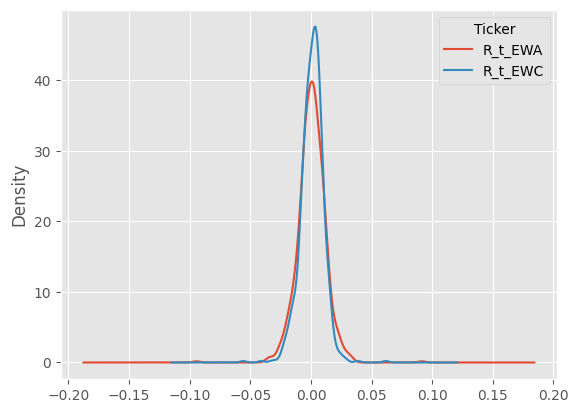

In [104]:
raw_data = yf.download(['EWA', 'EWC'], start='2023-11-01', end='2026-11-01')
df = raw_data['Close'].dropna().sort_index()

# Log prices
df['log_EWA'] = np.log(df['EWA'])
df['log_EWC'] = np.log(df['EWC'])
target_cols = ['log_EWA', 'log_EWC']

# Daily returns
df['R_t_EWA'] = df['log_EWA'].diff()
df['R_t_EWC'] = df['log_EWC'].diff()
target_cols_diff = ['R_t_EWA', 'R_t_EWC']

stats = df[target_cols_diff].apply(compute_stats)

print(stats)

df[target_cols_diff].plot(kind = 'kde')

### ADF
As expected, our data is I(1). Firstly, we fail to reject our null hypothesis for the ADF on log-prices.

In [105]:
# Perform Augmented Dickey-Fuller test on log-prices
adf = df[target_cols].apply(perform_adf)
adf

# Perform Augmented Dickey-Fuller test on log-returns
adf_diff = df[target_cols_diff].apply(perform_adf)
adf_diff


ADF Stat: -1.787699 , p-value: 0.386586
ADF Stat: -0.826345 , p-value: 0.811261
ADF Stat: -17.324412 , p-value: 0.000000
ADF Stat: -18.031387 , p-value: 0.000000


Ticker
R_t_EWA    None
R_t_EWC    None
dtype: object

In [106]:
split_idx = int(len(df) * 0.6)

train_df = df.iloc[:split_idx]
test_df = df.iloc[split_idx:]

coint_stat, p_value, crit_values = coint(train_df['log_EWA'], train_df['log_EWC'])
print(f"Stat: {coint_stat:.4f}, p-value: {p_value:.4f}, critical_values: {crit_values}")

Stat: -2.5204, p-value: 0.2702, critical_values: [-3.92094312 -3.34974169 -3.05388832]


### Analysis of 4 New Series
I have learned from my mistakes and decided to evaluate various pairs of financial assets. Out of the 4 pairs, 2 were cointegrated. Both are of order $I(1)$ and non-stationary, hence both main requisites for cointegration were satisfied. Mathematically, let $X_t \sim I(1)$ and $Y_t \sim I(1)$, they are cointegrated if there is some coefficient $\beta$ such that the residual spread is stationary: $$Z_t = Y_t - \beta X_t \sim I(0)$$

In [107]:
screen_pairs = [
    ('SPY', 'IVV'),
    ('GDX', 'GLD'),
    ('XLE', 'XOM'),
    ('GOOGL', 'GOOG')
]

def perform_adf(series):
    adf_stat, p_val, _, _, _, _ = adfuller(series)
    return p_val

for ticker_a, ticker_b in screen_pairs:
    raw_data = yf.download([ticker_a, ticker_b], start='2021-11-01', end='2026-11-01', progress=False)['Close']
    clean = raw_data[[ticker_a, ticker_b]].dropna().sort_index()
    split = int(len(clean) * 0.60)

    clean[f'log_{ticker_a}'] = np.log(clean[ticker_a])
    clean[f'log_{ticker_b}'] = np.log(clean[ticker_b])

    train = clean.iloc[:split]
    test = clean.iloc[split:]

    target_cols = [f'log_{ticker_a}', f'log_{ticker_b}']
    adf = clean[target_cols].apply(perform_adf)
    print(f"ADF Test on log-prices: [{ticker_a}-{ticker_b}] | p-values: {ticker_a}={adf.iloc[0]:.4e} | {ticker_b}={adf.iloc[1]:.4e}")
    adf_diff = clean[target_cols].diff().dropna().apply(perform_adf)
    print(f"ADF Test of Daily returns: [{ticker_a}-{ticker_b}] | p-values: {ticker_a}={adf_diff.iloc[0]:.4e} | {ticker_b}={adf_diff.iloc[1]:.4e}")

    y_a = np.log(clean[ticker_a])
    y_b = np.log(clean[ticker_b])

    stat, val, crit = coint(y_a, y_b)
    status = 'Yes (Cointegrated)' if val < 0.05 else 'No'
    print(f"[{ticker_a}-{ticker_b}]: Statistic: {stat:.4f} | p-val: {val:.4f} | critical-values: {crit} | cointegrated: {status}\n")


ADF Test on log-prices: [SPY-IVV] | p-values: SPY=9.5170e-01 | IVV=9.5360e-01
ADF Test of Daily returns: [SPY-IVV] | p-values: SPY=0.0000e+00 | IVV=0.0000e+00
[SPY-IVV]: Statistic: -4.3863 | p-val: 0.0019 | critical-values: [-3.90519489 -3.34100683 -3.04783387] | cointegrated: Yes (Cointegrated)

ADF Test on log-prices: [GDX-GLD] | p-values: GDX=8.8045e-01 | GLD=8.9958e-01
ADF Test of Daily returns: [GDX-GLD] | p-values: GDX=1.1715e-28 | GLD=0.0000e+00
[GDX-GLD]: Statistic: -2.5890 | p-val: 0.2413 | critical-values: [-3.90519489 -3.34100683 -3.04783387] | cointegrated: No

ADF Test on log-prices: [XLE-XOM] | p-values: XLE=6.7421e-01 | XOM=6.6193e-01
ADF Test of Daily returns: [XLE-XOM] | p-values: XLE=0.0000e+00 | XOM=0.0000e+00
[XLE-XOM]: Statistic: -3.1559 | p-val: 0.0776 | critical-values: [-3.90519489 -3.34100683 -3.04783387] | cointegrated: No

ADF Test on log-prices: [GOOGL-GOOG] | p-values: GOOGL=8.9773e-01 | GOOG=8.9475e-01
ADF Test of Daily returns: [GOOGL-GOOG] | p-values: GO

### Finding residuals $\hat{\epsilon}$
Now that we have established a cointegrated pair, we can move onto fitting the OLS to find the residuals $\hat{\epsilon}$ and fitting a second regression on them to calculate the expected time it takes for spread divergence to decay by 50%. Our end goal is to cancel the random walks of both series by finding a linear combination and projecting the comovement onto a 1-d residual coordinate: $$y_t = \alpha + \beta x_t + \epsilon_t \Rightarrow \epsilon_t = y_t - (\alpha + \beta x_t)$$
Essentially, we want to cancel the stochastic movement from one series with another and make their combination stationary. <br>
Looking at our fitted output, $\hat{\alpha} = 0.021866$ and $\hat{\beta} = 0.994189$. In log-space $\hat{\alpha} = \ln(P_{\text{GOOGL}}) - \hat{\beta} \ln(P_{\text{GOOG}})$. While financially, exponentiating $\hat{\alpha}$ represents the baseline price ratio multiplier $e^{0.021866} \approx \mathbf{1.0221}$. Or how much the market prices in the voting premium for Class A (GOOGL) shares, in our case, the market consensus prices the premium for voting rights at $\approx +2.21$%. <br>
On the other hand, $\hat{\beta}$ represents the static hedging ratio. In other words, how many shares of GOOG you must short when buying one share of GOOGL. For 1 share of GOOGL you must short 0.994189 shares of GOOG to eliminate systematic Alphabet equity risk.<br>
All in all, because $\hat{\beta} \approx 1$ and $R^2 = 0.9997$, we can conclude that the price movement of one share explains the movement of the other.

In [108]:
import statsmodels.api as sm
y_train = train['log_GOOGL']
x_train = train['log_GOOG']

X_train_c = sm.add_constant(x_train)
hedge_model = sm.OLS(y_train, X_train_c).fit()

alpha_hat = hedge_model.params['const']
beta_hat = hedge_model.params['log_GOOG']

print(f"Alpha (Intercept): {alpha_hat:.6f}")
print(f"Beta (Hedge Ratio): {beta_hat:.6f}")
print(f"R-squared: {hedge_model.rsquared:.4f}")
print(f"P-value (Beta): {hedge_model.pvalues['log_GOOG']:.4e}")

Alpha (Intercept): 0.021866
Beta (Hedge Ratio): 0.994189
R-squared: 0.9997
P-value (Beta): 0.0000e+00


### 0 Mean Residuals
Mathematically, the residuals are guaranteed to be 0 mean centered, this is because of the property of the OLS regression. Specifically, when we run an OLS: $y_i = \alpha + \beta xi + \epsilon_i$. The objective of the OLS is to choose estimates $\hat{\alpha}$ and $\hat{\beta}$ that minimise the Sum of Squared Residuals: $SSR(\alpha, \beta) = \sum_{i=1}^n \epsilon_i^2 = \sum_{i=1}^n (y_i - \alpha - \beta x_i)^2$. <br>
To find the minimum, we set the derivative of the $SSR$ wrt the intercept to 0 and solve: <br>
$$\frac{\partial SSR}{\partial \alpha} = \sum_{i=1}^n 2(y_i - \alpha - \beta x_i)^1 \cdot (-1) = 0$$
Dividing both sides by $-2$, we obtain: <br>
$$\sum_{i=1}^n (y_i - \alpha - \beta x_i) = 0$$ <br>
Notice that $(y_i - \alpha - \beta x_i) = \epsilon_i$, hence obtain the final results that the mean of residuals should be 0 when we divide by the sample size:<br>
$$\sum_{i=1}^n \epsilon_i = 0 \Rightarrow \bar{\hat{\epsilon}} = \frac{1}{n} \sum_{i=1}^n \hat{\epsilon}_i = \frac{0}{n} = \mathbf{0}$$<br>


In [109]:
#Res spread
epsilon_hat = y_train - alpha_hat - beta_hat * x_train
print(f'Residual mean: {epsilon_hat.mean():.4f}') # should be around -0.0

Residual mean: 0.0000


### Ornstein-Uhlenbeck (OU) Mean-Reversion OLS ($\tau_{1/2}$)
To find the mean-reversion speed and its half-time $\tau_{1/2}$ we must regress the differenced residuals $\Delta \hat{\epsilon}_t$ on lagged residuals $\hat{\epsilon}_t$. This is a standard practice when discretising the continuous Ornstein-Uhlenbeck process. This approach was popularised by Marco Avellaneda and Jeong-Hyun Lee in their seminal 2008 paper, "Statistical Arbitrage in the U.S. Equities Market." <br>
For the full picture, I will quickly go over this transformation. We start with the continuous-time Ornstein-Uhlenbeck Stochastic Differential Equation: $$dSt_t=\theta (\mu - S_t)dt+ \sigma dW_t$$ <br>
Since our data is daily, we let $dt \to \Delta t = 1$. Then replace the continuous derivative $dS_t$ with discrete daily change $S_t - S_{t-1}$ and $S_t$ with $S_{t-1}$. Lastly, we replace the Weiner process with the Gaussian shock $dW_t \to \sqrt{\Delta t} \, Z_t = \sqrt{1}Z_t = Z_t, \quad Z_t \sim \mathcal{N}(0, 1)$. <br>
Substituting everything back, we obtain $\Delta S_t \approx \theta (\mu - S_{t-1}) + \sigma Z_t$. When we rearrange into the standard linear regression form: $$\underbrace{\Delta S_t}_{y} \approx \underbrace{(\theta \mu)}_{\text{constant } a} + \underbrace{(-\theta)}_{\text{slope } b} \cdot \underbrace{S_{t-1}}_{x} + \underbrace{(\sigma Z_t)}_{\text{residual } u_t}$$ <br>
Lastly, it is important to point out why we use the residuals $\epsilon_t$ specifically instead of the asset price $S_t$. The reason for this is that an asset does not have a mean-reverting property, on the other hand, linear spread between two cointegrated ones do possess it. Hence:
$$\Delta \hat{\epsilon} = \alpha + \beta \hat{\epsilon_{t-1}} + u_t$$
On the practical side, there are a couple interesting implementation I would like to point out:
1. `ou_df = sm.add_constant(spread_lag.dropna())` prepends a column of 1's to our feature matrix $X$ because the computer calculates the OLS regression in matrix notation. Essentially, by adding a column of 1's we give the matrix equation to multiply the intercept $\alpha$ something against: $$X = \begin{bmatrix} 1 & \hat{\epsilon}_0 \\ 1 & \hat{\epsilon}_1 \\ \vdots & \vdots \\ 1 & \hat{\epsilon}_{T-1} \end{bmatrix}, \quad \boldsymbol{\beta} = \begin{bmatrix} a \\ b \end{bmatrix}$$ <br>
2. It is necessary to clarify that $\hat{b} \approx -\theta$ is the restoring pull. Meaning that, if $b$ is non-negative, the spread does not mean revert and our model is obsolete.
#### Results interpretation
`Mean Reversion Slope (b): -0.102577` <br>
`Speed of Reversion (theta): 0.108228` <br>
`Half-Life (tau_1/2): 6.40 trading days` <br>
`Calibrated Lookback (W): 6 days` <br>
A naive thought to have is that $b \approx -\theta$, however, the $0.005651$ between $b = -0.102577$ and $\theta = 0.108228$ is the difference in estimation. Without going too much into detail, this is the difference between discrete and continuous compounding. Specifically between a first-order approximation (Tayolr Series) and the exact exponential solution of the OU SDE. <br>
To summarise our results, whenever an earnings call, market shock or institutional order imbalance occurs and the linear spread between the two tickers widens. It takes 6.4 trading days for that gap to shrink by 50%. Every day, the market erases $10.28%$ of whatever price imbalance there was yesterday. Additionally, $\theta$ measures the restoring force acting on the spread.

In [110]:
spread_lag = epsilon_hat.shift(1)
spread_diff = epsilon_hat - spread_lag

ou_df = sm.add_constant(spread_lag.dropna())
ou_df.columns = ['const', 'spread_lag']
diff_clean = spread_diff.dropna()

ou_model = sm.OLS(diff_clean, ou_df).fit()

b_hat = ou_model.params['spread_lag']
a_hat = ou_model.params['const']

if b_hat >= 0:
  raise ValueError(
      "Spread is not mean-reverting: slope b is non-negative! (b ="
      f" {b_hat:.4f})"
  )

theta = -np.log(1 + b_hat)  # or approx -b_hat
half_life_days = np.log(2) / theta


lookback_W = max(5, int(round(half_life_days)))

print(f"Mean Reversion Slope (b): {b_hat:.6f}")
print(f"Speed of Reversion (theta): {theta:.6f}")
print(f"Half-Life (tau_1/2): {half_life_days:.2f} trading days")
print(f"Calibrated Lookback (W): {lookback_W} days")

Mean Reversion Slope (b): -0.102578
Speed of Reversion (theta): 0.108229
Half-Life (tau_1/2): 6.40 trading days
Calibrated Lookback (W): 6 days


### Phase 3: The Vectorized Signal Engine
Calculating Z-scores on 6 day rolling window and assigning a position. The entire idea behind this phase is that whenever the Z-score goes above $|1.25|$, we go long on the Class A shares and short Class C. We do so because a negative Z-score means that Class A shares (GOOGL) are underpriced relative to the Class C shares (GOOG), and as everyone has been taught, we buy the cheapest portfolio and sell the expensive one. Regarding the choice of Z-score, because this pair is highly cointegrated and most values lie around $1.25 - 2.00$, we can afford to choose the lower bound. Additionally, setting a stop-loss at 4 standard deviations away from the mean is also non-arbitrary. Mathematically, any value that is more than 4 standard deviations away or $\mathbb{P}(\vert{}Z\vert{} \ge 4.0)$ has a $\approx 0.006\%$ of occurring. That is $(\approx 1 \text{ in } 16,000 \text{ observations})$, which is almost never random noise.
<br>
Hence, if our spread has in fact widened above $|4.0|$, it could mean that the Cointegration Relationship has been broken, something fundamental has altered the relationship of these two stocks. An earning report, a large cash dividend, targeted buy-backs or a restructuring, etc. As a result, to prevent the algorithm from holding or buying in as $4\sigma \to 6\sigma \to 8\sigma$, we limit our losses and cash out at $4\sigma$.
Lastly, we should also take into the account that these are end-day prices, hence all of the big moves have been arbed out by big players.

In [111]:
clean['spread'] = clean['log_GOOGL'] - beta_hat * clean['log_GOOG']

#z-score
W = lookback_W
clean['rolling_mean'] = clean['spread'].rolling(window = W).mean()
clean['rolling_std'] = clean['spread'].rolling(window = W).std()
clean['rolling_std'] = clean['rolling_std'].replace(0, np.nan)
clean['z_score'] = (clean['spread'] - clean['rolling_mean'])/clean['rolling_std']

target_pos = pd.Series(np.nan, clean.index)
#long position, since the z-score is >=2 GOOGL is underpriced relative to GOOG. the spread will grow back to the mean.
target_pos[clean['z_score'] <= -1.25] = 1.00
#short position
target_pos[clean['z_score'] >= 1.25] = -1.00
target_pos[clean['z_score'].abs() >= 4.0] = 0.0

pos = pd.Series(np.nan, clean.index)
current_pos = 0.0

for t in range (W, len(clean)):
    z = clean['z_score'].iloc[t]
    if np.isnan(z):
        continue
    if abs(z) >= 4:
        current_pos = 0.0
    elif current_pos == 1.0 and z >= 0:
        current_pos = 0.0
    elif current_pos == -1.0 and z <= 0:
        current_pos = 0.0
    elif z <= -1.25:
        current_pos = 1.0
    elif z >= 1.25:
        current_pos = -1.0

    pos.iloc[t] = current_pos

clean['target_pos'] = pos

clean['actual_position'] = clean['target_pos'].shift(1).fillna(0.0)
clean['actual_position'].value_counts()

actual_position
 0.0    676
 1.0    303
-1.0    276
Name: count, dtype: int64

### Phase 4: The Vectorized Backtesting Engine
In this phase, we test our strategy on the test part of the dataset to ensure no lookahead biases are present and our algorithm correctly assigns positions. The logic is fairly simple, we calculate the daily returns of the log-prices. We assume 0.0001\\$ of transaction costs per trade. Lastly, compute the metrics. Where the Sharpe Ratio is the average of the return differentials divided by the standard deviation. Our results show a modest decay of the Sharpe Ratio when we apply the algorithms OOS. Importantly, our annualised volatility has remained largely the same, which is remarkable. It is stable and low. Consequently, our Sharpe Ratio has retained 97.7% of its in-sample efficiency. With a tightly contained loss of $\approx 1%$ which means that strategy is successful. To showcase this, I have prepared two graphs represent the dual equity curve plot and the maximum drawdown chart.

In [150]:
clean['ret_GOOGL'] = clean['log_GOOGL'].diff(1)
clean['ret_GOOG'] = clean['log_GOOG'].diff(1)

clean['ret_spread'] = clean['ret_GOOGL'] - beta_hat * clean['ret_GOOG']
clean['strat_ret_gross'] = clean['ret_spread'] * clean['actual_position']

cost_per_trade = 0.0001
clean['trades'] = clean['actual_position'].diff().abs().fillna(0)
clean['strat_ret_net'] = clean['strat_ret_gross'] - (clean['trades'] * cost_per_trade)

clean['equity_gross'] = (1 + clean['strat_ret_gross']).cumprod()
clean['equity_net'] = (1 + clean['strat_ret_net']).cumprod()

def compute_metrics(returns):
    ret = returns.dropna()
    ann_return = ret.mean() * 252
    ann_vol = ret.std() * np.sqrt(252)
    sharpe = ann_return / ann_vol if ann_vol > 0 else 0.0

    # Max Drawdown
    cum_ret = (1.0 + ret).cumprod()
    running_max = cum_ret.cummax()
    drawdown = (cum_ret - running_max) / running_max
    max_dd = drawdown.min()

    return {
        "Annualised Return": f"{ann_return * 100:.2f}%",
        "Annualised Vol": f"{ann_vol * 100:.2f}%",
        "Sharpe": f"{sharpe:.2f}",
        "Max Drawdown": f"{max_dd * 100:.2f}%"
    }

print('In Sample metrics: ', compute_metrics(clean['strat_ret_net'].iloc[:split_idx]))
print('Out of Sample Metrics: ', compute_metrics(clean['strat_ret_net'].iloc[split_idx:]))
print('Total trades: ', clean.loc[clean['trades'] != 0, 'trades'].count())

In Sample metrics:  {'Annualised Return': '4.03%', 'Annualised Vol': '1.84%', 'Sharpe': '2.19', 'Max Drawdown': '-0.96%'}
Out of Sample Metrics:  {'Annualised Return': '3.46%', 'Annualised Vol': '1.62%', 'Sharpe': '2.14', 'Max Drawdown': '-0.96%'}
Total trades:  327


### Visualisations

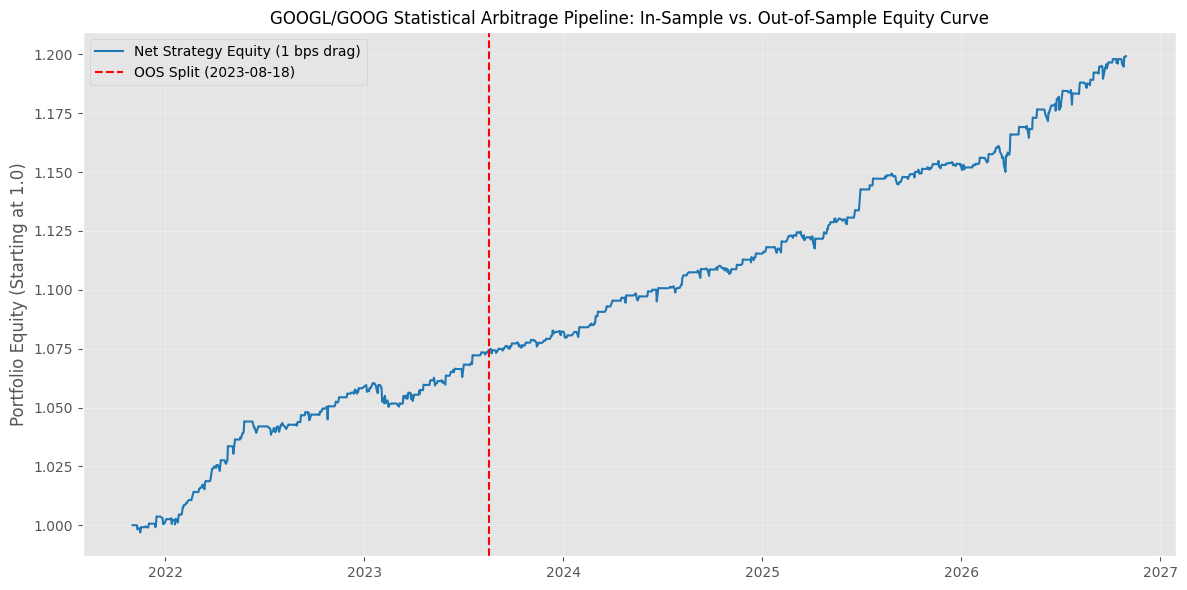

In [151]:
plt.figure(figsize=(12, 6))
plt.plot(clean.index, clean['equity_net'], label='Net Strategy Equity (1 bps drag)', color='#1f77b4', lw=1.5)

# Benchmark / Buy & Hold Comparison (optional: GOOGL or 50/50)
split_date = clean.index[split_idx]
plt.axvline(x=split_date, color='red', linestyle='--', label=f'OOS Split ({split_date.strftime("%Y-%m-%d")})')

plt.title('GOOGL/GOOG Statistical Arbitrage Pipeline: In-Sample vs. Out-of-Sample Equity Curve', fontsize=12)
plt.ylabel('Portfolio Equity (Starting at 1.0)')
plt.grid(True, alpha=0.3)
plt.legend(loc='upper left')
plt.tight_layout()
plt.show()

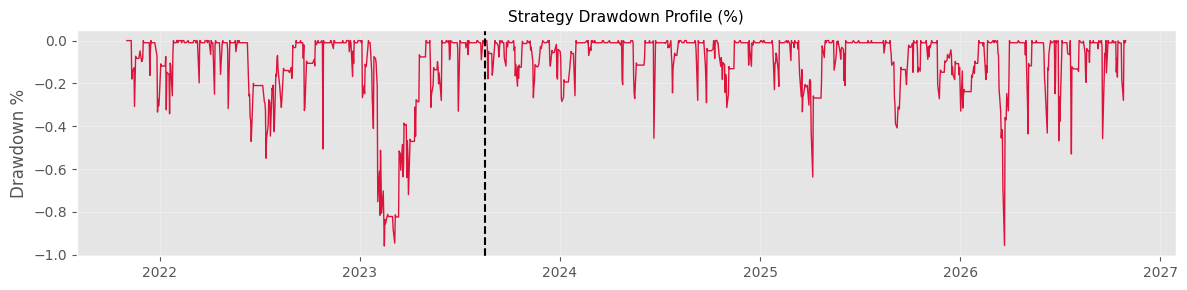

In [121]:
plt.figure(figsize=(12, 3))
cum_net = clean['equity_net']
running_max = cum_net.cummax()
dd = (cum_net - running_max) / running_max

plt.plot(clean.index, dd * 100, color='crimson', lw=1)
plt.axvline(x=split_date, color='black', linestyle='--', label='OOS Split')
plt.title('Strategy Drawdown Profile (%)', fontsize=11)
plt.ylabel('Drawdown %')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()